# A simulated tissue, from Python

SituCraft makes this tissue on your computer, in seconds, with its truth: cells of four types, each expressing its own markers, imaged as a Xenium run would image them. This notebook drives SituCraft from Python (the `situcraft` package in `clients/python`): it checks the run's metrics, clusters and labels the cells, measures the labels against the true types, asks which labels neighbor each other, shows the tissue, and saves the recipe that makes it all again.

Start SituCraft with remote control first (`situcraft --remote-control`); the open window shows each step as it happens. It needs pandas and matplotlib.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

import situcraft

sc = situcraft.connect(client="simulated-tissue notebook")
opened = sc.open_example("simulated")
state = sc.get_state()
project = state["project"]["name"]
bundle = Path(state["datasets"][0]["path"])
print(opened.message)

Opened A simulated tissue with known truth in simulated-standard.


## The run's metrics

SituCraft recomputes from the data what it can of the run's own metrics; each one it recomputes should agree.

In [2]:
metrics = sc.qc_metrics().frame("metrics")[["label", "recorded", "computed", "agrees"]]
assert metrics["agrees"].dropna().all(), "every metric SituCraft recomputes agrees with the run's"
metrics.head(8)

,label,recorded,computed,agrees
0,Region area,250000.000000,NaN,None
1,Total cell area,245476.509687,245476.509687,True
2,Cells,2925.000000,2925.000000,True
3,Share of cells with no gene transcript,0.000000,0.000000,True
4,Gene transcripts of quality 20 or more,394507.000000,394507.000000,True
5,Share of gene transcripts of quality 20 or more,0.910677,0.910677,True
6,Gene transcripts per 100 µm² of cell,160.710693,160.710693,True
7,Share of gene transcripts in cells,0.987863,0.987863,True


## Cell types

The cells are clustered with SituCraft's defaults and labeled from the simulated tissue's own marker set. The truth folder of the bundle names each cell's true type; imported, it is a label set like any other.

In [3]:
clusters = sc.cluster_cells()
labels = sc.label_cells(markers="simulated")
truth = sc.import_labels(path=str(bundle / "truth" / "instrument_cell_types.csv"), id_column="cell_id", column="cell_type")
for result in (clusters, labels, truth):
    print(result.message)

Instrument segmentation of simulated-standard: 5 clusters of 2,925 cells (resolution 1, modularity 0.7166); the largest's leading markers SIM021, SIM018, SIM019.
Clusters of Instrument segmentation, resolution 1 labeled by Simulated tissue's types: type 99% of 2,925 cells.
cell_type from instrument_cell_types.csv imported for Instrument segmentation of simulated-standard: 4 labels, 2,925 cells of 2,925 labeled.


## The labels against the truth

`query_cells` keeps the cells a tree of conditions says (here: the cells of one true type) and divides them by another label set's labels (`by`): each true type's cells by the label SituCraft gave them.

In [4]:
true_types = sorted(sc.get_result(truth["id"], limit=0).frame()["label"])
rows = {}
for true_type in true_types:
    kept = sc.query_cells({"labels": truth["id"], "in": [true_type]}, project=project, by=labels["id"])
    composition = kept.frame("composition")
    rows[true_type] = composition.set_index("name")["kept"]
confusion = pd.DataFrame(rows).T.fillna(0).astype(int)
agreement = sum(confusion.loc[t, t] for t in true_types if t in confusion.columns) / confusion.values.sum()
print(f"{agreement:.1%} of the cells labeled as their true type")
assert agreement > 0.9, "the labels agree with the true types"
confusion

97.0% of the cells labeled as their true type


name,epithelial-like,fibroblast-like,immune-like,endothelial-like,none
endothelial-like,2,0,0,619,2
epithelial-like,593,0,0,0,0
fibroblast-like,4,630,0,0,3
immune-like,22,6,996,15,33


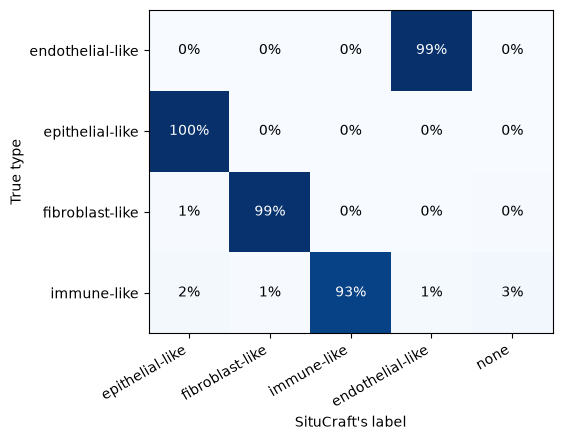

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
shares = confusion.div(confusion.sum(axis=1), axis=0)
ax.imshow(shares.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(shares.columns)), shares.columns, rotation=30, ha="right")
ax.set_yticks(range(len(shares.index)), shares.index)
ax.set_xlabel("SituCraft's label")
ax.set_ylabel("True type")
for i in range(shares.shape[0]):
    for j in range(shares.shape[1]):
        ax.text(j, i, f"{shares.values[i, j]:.0%}", ha="center", va="center", color="white" if shares.values[i, j] > 0.5 else "black")
fig.tight_layout()
fig.savefig("labels-against-truth.png", dpi=150)

## Which labels neighbor each other

A Delaunay graph of the cells, and each pair of labels' neighbors against the number expected if the labels were dealt to the same cells at random, with a z-score from seeded permutations.

In [6]:
sc.build_graph()
enrichment = sc.spatial_analysis(question="enrichment", labels=labels["id"])
pairs = sc.get_result(enrichment["id"], limit=0).frame("table")
z = pairs.pivot(index="a", columns="b", values="z")
assert all(z.loc[t, t] > 0 for t in z.index), "each type's cells neighbor their own kind more often than at random"
z.round(1)

b,endothelial-like,epithelial-like,fibroblast-like,immune-like
a,,,,
endothelial-like,29.5,-26.0,-21.3,5.4
epithelial-like,-26.0,30.3,12.8,-23.3
fibroblast-like,-21.3,12.8,15.3,-10.6
immune-like,5.4,-23.3,-10.6,15.1


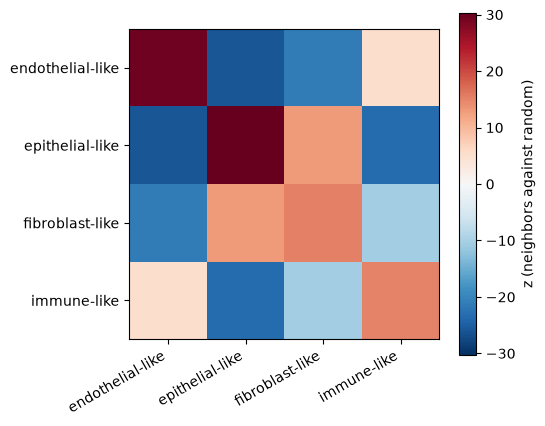

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
limit = abs(z.values).max()
image = ax.imshow(z.values, cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.set_xticks(range(len(z.columns)), z.columns, rotation=30, ha="right")
ax.set_yticks(range(len(z.index)), z.index)
fig.colorbar(image, label="z (neighbors against random)")
fig.tight_layout()
fig.savefig("neighborhood-enrichment.png", dpi=150)

## The tissue

The tissue as the Viewer shows it, each cell filled by its label, as a picture.

simulated-standard in the Viewer at (250, 250) µm, 1.27 µm per pixel; a picture of it, 800 × 960 pixels.


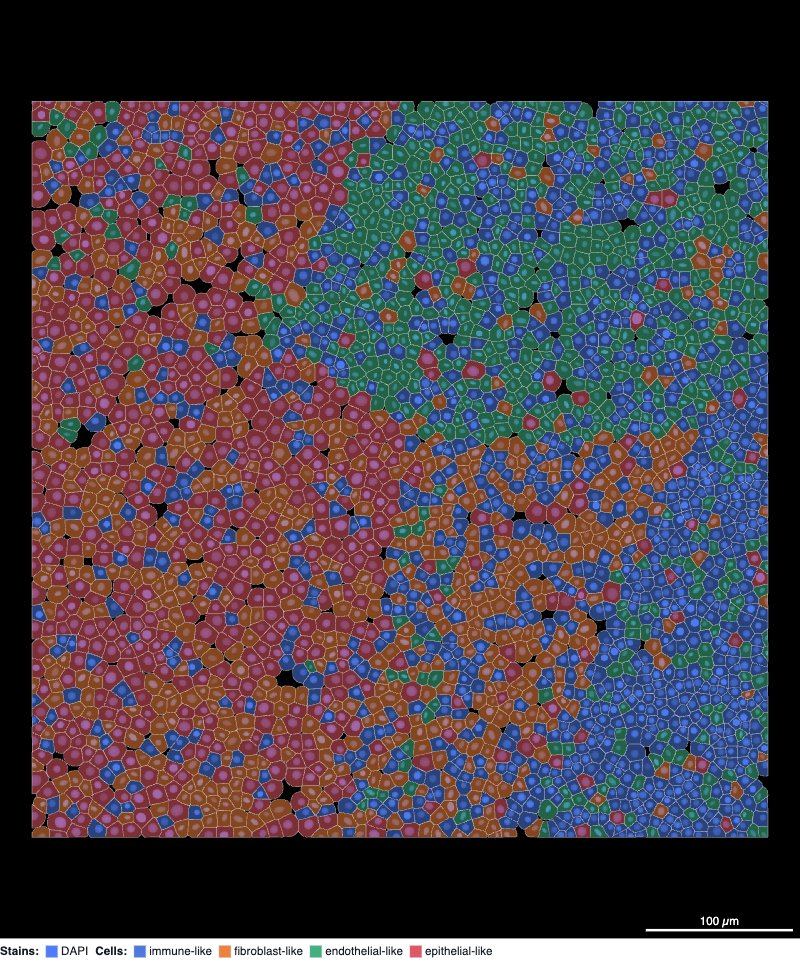

In [8]:
shown = sc.show_tissue(fill="labels", whole=True, picture_width=800, file="tissue.jpg")
print(shown.message)
display(Image("tissue.jpg"))

## The recipe

The enrichment's recipe: every step from the bundle to it, as readable JSON. `situcraft run --recipe neighborhood-enrichment.recipe.json --bundle <bundle> --out <folder>` makes it again without a window, on this bundle or another, with a certificate anyone can check.

In [9]:
recipe = sc.recipe(enrichment["id"])
Path("neighborhood-enrichment.recipe.json").write_text(json.dumps(recipe.data, indent=1) + "\n")
for step in recipe["steps"]:
    print(f'{step["n"]}. {step["name"]} ({step["job"]})')
assert recipe["steps"][-1]["made"] == enrichment["id"]

1. Instrument segmentation (segmentation)
2. Delaunay graph of Instrument segmentation, edges to 50 µm (graph)
3. Clusters of Instrument segmentation, resolution 1 (clustering)
4. Labels of Clusters of Instrument segmentation, resolution 1 by Simulated tissue's types (labels)
5. Neighborhood enrichment of Labels by Simulated tissue's types: type, Delaunay graph of Instrument segmentation, edges to 50 µm (spatial)
